# DJ Transition Engine

**Jayesh (IS24BM008) — IIT Dharwad — Data Mining Project**

Given two songs that sound very different, this notebook builds an ordered chain of real
tracks from the Spotify 1921-2020 dataset that gradually bridges them — the way a skilled
DJ builds a set. Mechanically: a k-nearest-neighbour graph over the 10 continuous audio
features (standardized with the shared scaler), and Dijkstra's shortest-path algorithm between
any two songs on that graph, with squared edge weights so the path prefers several small steps
over one big jump.

This notebook consumes the output of the shared preprocessing notebook
(`data/tracks_100k.parquet`, `data/scaler.joblib`) as-is. **No re-preprocessing, no
re-fitting the scaler.**

**Feature set.** `mode` (binary major/minor) and `time_signature` (a near-constant category)
are left out of the graph, the same choice as the Music Tribes module. Standardized, a
major/minor flip alone costs 2.1 units — more than 99% of the graph's edges — so with `mode`
included the graph treats a change of key as one of the biggest possible jumps while ignoring
which key a song is actually in.

**Contents**
1. Setup
2. Load data
3. Build the k-NN graph
4. Connectivity sanity check
5. Save the graph
6. `find_transition` (Dijkstra) and the edge weights
7. Test cases — three demo transitions
8. How smooth are the transitions? (1000 random pairs, five methods)
9. Which audio features move most along typical paths?
10. Curated paths export for the website
11. Verification (fresh-session reload)

## 1. Setup

In [1]:
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix, save_npz, load_npz
from scipy.sparse.csgraph import (connected_components, dijkstra,
                                  minimum_spanning_tree, breadth_first_order)

SEED = 42
np.random.seed(SEED)

# Fixed order of the 12 audio features the scaler was fit on. Order matters —
# the scaler has no feature-name metadata, so columns must be passed in this
# exact sequence or every downstream distance is silently wrong.
AUDIO_FEATURES = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms", "mode", "time_signature",
]
# The graph uses the 10 continuous features (same choice as the Music Tribes module).
GRAPH_FEATURES = [f for f in AUDIO_FEATURES if f not in ("mode", "time_signature")]
K_NEIGHBORS = 15   # real neighbours per song; the song itself is not counted

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

TRACKS_PATH = DATA_DIR / "tracks_100k.parquet"
SCALER_PATH = DATA_DIR / "scaler.joblib"

assert TRACKS_PATH.exists(), f"Missing input file: {TRACKS_PATH}"
assert SCALER_PATH.exists(), f"Missing input file: {SCALER_PATH}"
print(f"Found {TRACKS_PATH} ({TRACKS_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Found {SCALER_PATH} ({SCALER_PATH.stat().st_size / 1e3:.1f} KB)")

Found data\tracks_100k.parquet (12.2 MB)
Found data\scaler.joblib (0.9 KB)


## 2. Load data

Load the cleaned tracks and the already-fitted `StandardScaler` from the preprocessing
notebook. The scaler was fit on the full 523k-track cleaned corpus, so it's the shared
"source of truth" for standardization across every module in the project — this notebook only calls
`.transform()`, never `.fit()`. It standardizes all 12 features; the graph keeps the 10
continuous columns.

In [2]:
tracks = pd.read_parquet(TRACKS_PATH)
scaler = joblib.load(SCALER_PATH)

print(f"tracks: {tracks.shape[0]:,} rows x {tracks.shape[1]} columns")
assert tracks["id"].is_unique, "Expected one row per Spotify track id"

X = tracks[AUDIO_FEATURES].values
X_scaled = scaler.transform(X)                      # all 12 standardized features
GRAPH_IDX = [AUDIO_FEATURES.index(f) for f in GRAPH_FEATURES]
X_graph = X_scaled[:, GRAPH_IDX]                    # the 10 the graph is built on

print(f"X_scaled shape: {X_scaled.shape}  ->  X_graph shape: {X_graph.shape}")
print("first 3 rows of X_graph:")
print(np.round(X_graph[:3], 3))

tracks: 100,001 rows x 28 columns
X_scaled shape: (100001, 12)  ->  X_graph shape: (100001, 10)
first 3 rows of X_graph:
[[-0.57  -1.771 -1.162  0.174  1.55  -0.422  0.486 -1.74  -1.369 -0.014]
 [ 1.17  -1.012  0.17  -0.126  1.562  0.285 -0.194  0.78   0.128 -0.543]
 [-0.377 -1.74  -2.289 -0.126  1.565  2.611 -0.556 -0.486  0.017 -0.56 ]]


C:\Users\980ja\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [3]:
# Sanity check: standardizing with a scaler fit on the full 523k corpus should still
# leave this 100k subset with column means ~0 and stds ~1, *if* the subset is a
# representative sample. Large deviations here would flag a biased subset.
means = X_scaled.mean(axis=0)
stds = X_scaled.std(axis=0)

print("column means (expect ~0):")
print(np.round(means, 3))
print("column stds  (expect ~1):")
print(np.round(stds, 3))

assert np.all(np.abs(means) < 0.1), "Standardized means drifted further from 0 than expected"
assert np.all(np.abs(stds - 1) < 0.1), "Standardized stds drifted further from 1 than expected"
print("\nOK: 100k subset is standardized consistently with the full corpus.")

column means (expect ~0):
[-0.002  0.    -0.001  0.001 -0.003 -0.001 -0.001 -0.004 -0.    -0.001
  0.004 -0.002]
column stds  (expect ~1):
[1.    1.001 0.999 1.003 1.    0.998 0.998 1.    0.999 0.976 0.999 1.006]

OK: 100k subset is standardized consistently with the full corpus.


## 3. Build the k-NN graph

Each song becomes a node; each song connects to its 15 nearest neighbours (Euclidean
distance in the standardized 10-D feature space), with the edge weight equal to that
distance. `ball_tree` is used because Euclidean-metric queries in a modest number of
dimensions (10) are exactly what ball trees are built for — much faster than a brute-force
scan at this scale.

The search asks for 16 neighbours and drops the song itself. The song is **not** always in
column 0: when several tracks have identical audio profiles (distance 0), any of them can come
first, so self-matches are removed by index rather than by position. Identical profiles also
produce zero-length edges; some scipy graph routines (e.g. `minimum_spanning_tree`) treat a
stored 0 as a missing edge, so zero distances are stored as 1e-9.

This is the slowest cell in the notebook (nearest-neighbour search over 100k points) —
expect a few minutes.

In [4]:
t0 = time.time()

nbrs = NearestNeighbors(n_neighbors=K_NEIGHBORS + 1, algorithm="ball_tree", metric="euclidean")
nbrs.fit(X_graph)
distances, indices = nbrs.kneighbors(X_graph)

knn_fit_query_time = time.time() - t0
print(f"k-NN fit + query took {knn_fit_query_time:.1f}s for {X_graph.shape[0]:,} nodes")

k-NN fit + query took 95.6s for 100,001 nodes


In [5]:
t0 = time.time()

n_nodes = X_graph.shape[0]
is_self = indices == np.arange(n_nodes)[:, None]
print(f"Rows where the song itself is not in column 0: {(~is_self[:, 0]).sum():,}")

# Keep the first K_NEIGHBORS entries of each row that are not the song itself.
# A stable sort on is_self moves the self-match to the end and keeps the rest in distance order.
order = np.argsort(is_self, axis=1, kind="stable")
nbr_idx = np.take_along_axis(indices, order, axis=1)[:, :K_NEIGHBORS]
nbr_dist = np.take_along_axis(distances, order, axis=1)[:, :K_NEIGHBORS]
assert not (nbr_idx == np.arange(n_nodes)[:, None]).any(), "A self-loop is left in the graph"

rows = np.repeat(np.arange(n_nodes), K_NEIGHBORS)
cols = nbr_idx.ravel()
data = np.maximum(nbr_dist.ravel(), 1e-9)   # keep zero-distance pairs as (near-zero) edges

knn_graph = csr_matrix((data, (rows, cols)), shape=(n_nodes, n_nodes))

graph_build_time = time.time() - t0
print(f"Sparse adjacency matrix built in {graph_build_time:.2f}s")
print(f"Graph: {knn_graph.shape[0]:,} nodes, {knn_graph.nnz:,} directed edges "
      f"({K_NEIGHBORS} per node)")
print(f"Edge length: median {np.median(data):.3f}, 99th percentile {np.quantile(data, 0.99):.3f}, "
      f"max {data.max():.3f}")

Rows where the song itself is not in column 0: 91
Sparse adjacency matrix built in 0.13s
Graph: 100,001 nodes, 1,500,015 directed edges (15 per node)
Edge length: median 0.758, 99th percentile 1.929, max 16.697


## 4. Connectivity sanity check

A k-NN graph is not guaranteed to be a single connected component — an isolated cluster
of songs with no edges to the rest of the graph would make Dijkstra fail to find a path
between it and everything else. This is checked before relying on the graph for anything.

In [6]:
n_components, labels = connected_components(knn_graph, directed=False)

print(f"Connected components: {n_components}")

component_sizes = pd.Series(labels).value_counts().sort_values(ascending=False)
print("Component sizes (largest first):")
print(component_sizes.to_string())

if n_components > 1:
    largest_frac = component_sizes.iloc[0] / n_nodes
    print(f"\nWARNING: graph is not fully connected ({n_components} components). "
          f"Largest component covers {largest_frac:.1%} of nodes. "
          "Increasing k would likely stitch the smaller components in. "
          "For now, the DJ Engine only guarantees a path between two songs that "
          "both live in the largest component.")
else:
    print("\nGraph is fully connected — every song can reach every other song.")

Connected components: 1
Component sizes (largest first):
0    100001

Graph is fully connected — every song can reach every other song.


## 5. Save the graph

Persist the sparse graph and the song-id <-> node-index lookup so other notebooks (or a
future session of this one) can reuse them without rebuilding. `save_npz`/`json` only —
no pickle, so the artifacts are portable and human-inspectable. The graph is saved with plain
Euclidean edge lengths; the squared weights used for search (§6) are derived from it on load.

In [7]:
GRAPH_PATH = OUT_DIR / "knn_graph.npz"
INDEX_PATH = OUT_DIR / "song_index.json"

save_npz(GRAPH_PATH, knn_graph)

id_to_idx = {song_id: int(i) for i, song_id in enumerate(tracks["id"])}
idx_to_id = {int(i): song_id for song_id, i in id_to_idx.items()}

with open(INDEX_PATH, "w", encoding="utf-8") as f:
    json.dump({"id_to_idx": id_to_idx, "idx_to_id": idx_to_id}, f)

print(f"Saved graph to {GRAPH_PATH} ({GRAPH_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"Saved index to {INDEX_PATH} ({INDEX_PATH.stat().st_size / 1e6:.2f} MB)")

Saved graph to outputs\knn_graph.npz (15.41 MB)
Saved index to outputs\song_index.json (6.78 MB)


## 6. `find_transition` and the edge weights

Runs single-source Dijkstra from `start_song_id` and walks the predecessor array
backwards from `end_song_id` to reconstruct the cheapest path on the graph it is given.

**Edge weights.** Dijkstra minimises the *sum* of edge weights. With plain distances, one big
jump costs exactly as much as two half-size steps, so nothing discourages the big jump. Squaring
each edge weight changes that: one step of length 1 costs 1, while two steps of length 0.5 cost
0.25 + 0.25 = 0.5. The search then prefers several small, gradual moves, which is what a DJ
wants. Section 8 measures the effect on 1000 random pairs; the squared graph is the engine's
default (`DJ_GRAPH`).

In [8]:
def find_transition(
    start_song_id: str,
    end_song_id: str,
    graph: csr_matrix,
    id_to_idx: dict,
    idx_to_id: dict,
    tracks_df: pd.DataFrame,
) -> tuple[list, pd.DataFrame, float]:
    """Find the smoothest chain of songs from start_song_id to end_song_id.

    Runs Dijkstra's shortest-path algorithm on the k-NN graph and reconstructs
    the path from the predecessor array.

    Returns:
        path_ids: song IDs in order, starting with start_song_id and ending with
            end_song_id. Empty if end_song_id is unreachable from start_song_id.
        path_df: DataFrame of every song in the path (in order), with all columns
            from tracks_df. Empty (0 rows) if unreachable.
        total_weight: sum of the graph's edge weights along the path (squared
            distances for DJ_GRAPH). float('inf') if end_song_id is unreachable
            (different connected component).
    """
    for song_id, label in [(start_song_id, "start_song_id"), (end_song_id, "end_song_id")]:
        if song_id not in id_to_idx:
            raise KeyError(f"{label}={song_id!r} not found in the song index")

    start_idx = id_to_idx[start_song_id]
    end_idx = id_to_idx[end_song_id]

    if start_idx == end_idx:
        row = tracks_df.loc[tracks_df["id"] == start_song_id]
        return [start_song_id], row, 0.0

    dist, predecessors = dijkstra(
        graph, directed=False, indices=start_idx, return_predecessors=True
    )

    if np.isinf(dist[end_idx]):
        return [], tracks_df.iloc[0:0], float("inf")

    path_idx = [end_idx]
    cur = end_idx
    while cur != start_idx:
        cur = predecessors[cur]
        path_idx.append(cur)
    path_idx.reverse()

    path_ids = [idx_to_id[i] for i in path_idx]
    path_df = tracks_df.set_index("id").loc[path_ids].reset_index()
    total_weight = float(dist[end_idx])
    return path_ids, path_df, total_weight

In [9]:
# The two weightings compared in Section 8. Squaring element-wise keeps exactly the same edges.
knn_graph_sq = knn_graph.power(2)
DJ_GRAPH = knn_graph_sq   # the engine's default: squared distances

In [10]:
def get_song_id(name_substr: str, artist_substr: str = None, tracks_df: pd.DataFrame = tracks) -> str:
    """Look up a single track's Spotify id by case-insensitive name/artist substring.

    Raises ValueError if no track matches. If several match, picks the most
    popular one and prints a warning (some titles are re-released many times).
    """
    mask = tracks_df["name"].str.contains(name_substr, case=False, na=False, regex=False)
    if artist_substr:
        mask &= tracks_df["primary_artist_name"].str.contains(artist_substr, case=False, na=False, regex=False)
    matches = tracks_df.loc[mask]
    if len(matches) == 0:
        raise ValueError(f"No track found for name={name_substr!r}, artist={artist_substr!r}")
    if len(matches) > 1:
        print(f"  ({len(matches)} matches for name={name_substr!r}, artist={artist_substr!r} "
              "-> using the most popular)")
        matches = matches.sort_values("popularity", ascending=False)
    return matches.iloc[0]["id"]


def path_steps(path_ids: list) -> np.ndarray:
    """Length of each hop along a path, in the 10-D standardized space the graph uses."""
    idx = [id_to_idx[i] for i in path_ids]
    return np.linalg.norm(np.diff(X_graph[idx], axis=0), axis=1)


def display_path(path_df: pd.DataFrame, title: str) -> None:
    """Pretty-print a transition as a table, with the size of each step."""
    display_cols = ["name", "primary_artist_name", "decade", "popularity",
                    "danceability", "energy", "valence", "acousticness"]
    steps = path_steps(path_df["id"].tolist())
    print(f"\n=== {title} ===")
    print(f"{len(path_df)} songs in the chain | largest step = {steps.max():.3f} | "
          f"total distance = {steps.sum():.3f}\n")
    table = path_df[display_cols].rename(columns={"primary_artist_name": "artist"}).reset_index(drop=True)
    table.insert(0, "step", np.r_[np.nan, steps].round(3))
    display(table)

## 7. Test cases

Three real, well-known transitions, chosen to exercise different parts of the feature
space:

- **Test 1 — ballad to EDM drop**: Adele's *Someone Like You* (slow, acoustic, low
  energy) to Avicii's *Wake Me Up (EDX Miami Sunset Remix)* (high-energy EDM). Expect a
  long path that raises energy and strips out the acoustic sound step by step.
- **Test 2 — similar style**: two Ed Sheeran tracks with close audio profiles. Expect a
  short path.
- **Test 3 — cross-decade jump**: The Beatles' *Hello, Goodbye* (1967) to Dua Lipa's
  *Levitating* (2020). Release year is not a feature, so nothing pulls the path through the
  decades in between: it bridges on sound alone, and the `decade` column shows it moving
  freely between eras.

The `step` column is each song's distance from the previous one in the 10-D standardized space.

In [11]:
test1_start = get_song_id("Someone Like You", "Adele")
test1_end = get_song_id("Wake Me Up", "Avicii")

test1_path_ids, test1_path_df, test1_weight = find_transition(
    test1_start, test1_end, DJ_GRAPH, id_to_idx, idx_to_id, tracks
)
display_path(test1_path_df, "Test 1: Adele - Someone Like You  -->  Avicii - Wake Me Up (EDX Remix)")


=== Test 1: Adele - Someone Like You  -->  Avicii - Wake Me Up (EDX Remix) ===


17 songs in the chain | largest step = 0.722 | total distance = 8.006



,step,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,NaN,Someone Like You,Adele,2010,80,0.556,0.319,0.294,0.89300
1,0.466,Que Lloro (with Carla Morrison),Leonel García,2010,59,0.550,0.352,0.283,0.84400
2,0.502,寂寞的眼,Wakin Chau,1980,27,0.569,0.422,0.338,0.76900
3,0.347,Al Dios Eterno,Su Presencia,2010,33,0.558,0.444,0.342,0.69700
4,0.393,愛你是我一生中理想,Sammi Cheng,1990,32,0.532,0.486,0.346,0.62600
5,0.392,Não Morrerei,Marquinhos Gomes,2010,55,0.526,0.514,0.405,0.54700
6,0.509,ลูกทุ่งคนยาก,เอกราช สุวรรณภูมิ,1990,11,0.549,0.529,0.432,0.40500
7,0.555,潮風にちぎれて,Yumi Matsutoya,2000,30,0.559,0.609,0.467,0.28100
8,0.494,Sweet Painted Lady,John Grant,1970,24,0.538,0.561,0.505,0.19300
9,0.590,Dronk Wees,Akkedis,1990,11,0.561,0.620,0.541,0.08300


In [12]:
test2_start = get_song_id("Nancy Mulligan", "Ed Sheeran")
test2_end = get_song_id("New Man", "Ed Sheeran")

test2_path_ids, test2_path_df, test2_weight = find_transition(
    test2_start, test2_end, DJ_GRAPH, id_to_idx, idx_to_id, tracks
)
display_path(test2_path_df, "Test 2: Ed Sheeran - Nancy Mulligan  -->  Ed Sheeran - New Man")


=== Test 2: Ed Sheeran - Nancy Mulligan  -->  Ed Sheeran - New Man ===
4 songs in the chain | largest step = 0.572 | total distance = 1.560



,step,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,NaN,Nancy Mulligan,Ed Sheeran,2010,67,0.680,0.852,0.858,0.1170
1,0.432,Hey Yeah!,櫻井 翔,2010,36,0.675,0.828,0.923,0.0686
2,0.572,Ever Blazin',Sean Paul,2000,44,0.753,0.771,0.910,0.0280
3,0.556,New Man,Ed Sheeran,2010,69,0.780,0.745,0.862,0.0559


In [13]:
test3_start = get_song_id("Hello, Goodbye", "Beatles")
test3_end = get_song_id("Levitating", "Dua Lipa")

test3_path_ids, test3_path_df, test3_weight = find_transition(
    test3_start, test3_end, DJ_GRAPH, id_to_idx, idx_to_id, tracks
)
display_path(test3_path_df, "Test 3: The Beatles - Hello, Goodbye (1967)  -->  Dua Lipa - Levitating (2020)")


=== Test 3: The Beatles - Hello, Goodbye (1967)  -->  Dua Lipa - Levitating (2020) ===
8 songs in the chain | largest step = 0.850 | total distance = 3.650



,step,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,NaN,"Hello, Goodbye - Remastered 2009",The Beatles,1960,66,0.479,0.733,0.806,0.3060
1,0.850,There in Your Eyes,Chas & Dave,1980,19,0.561,0.764,0.825,0.1590
2,0.465,Sueña,Orquesta Candela,2010,38,0.600,0.724,0.840,0.1440
3,0.677,Dobre myśli,Sylwia Grzeszczak,2010,46,0.667,0.772,0.881,0.1120
4,0.261,Safe,Bay Ledges,2010,56,0.692,0.790,0.872,0.1320
5,0.476,Cuando Estamos Juntos,Potencia,2000,45,0.743,0.790,0.870,0.1970
6,0.460,Love Not War (The Tampa Beat),Jason Derulo,2020,86,0.738,0.850,0.865,0.1050
7,0.460,Levitating,Dua Lipa,2020,82,0.695,0.884,0.914,0.0561


In [14]:
for name, ids in [("Test 1", test1_path_ids), ("Test 2", test2_path_ids), ("Test 3", test3_path_ids)]:
    steps = path_steps(ids)
    print(f"{name}: {len(ids) - 1:2d} hops | largest step {steps.max():.3f} | total distance {steps.sum():.3f}")

Test 1: 16 hops | largest step 0.722 | total distance 8.006
Test 2:  3 hops | largest step 0.572 | total distance 1.560
Test 3:  7 hops | largest step 0.850 | total distance 3.650


## 8. How smooth are the transitions?

A DJ judges a transition by its **worst jump**: one jarring cut spoils a set even if every
other step is small. So the main measure is the **largest single step** on each path (Euclidean
distance in the 10-D standardized space), alongside the number of hops.

Five ways of getting from song A to song B are compared on the same 1000 random pairs
(both endpoints drawn uniformly from all songs):

| method | what it does |
|---|---|
| direct jump | play B straight after A — the no-DJ baseline |
| straight line | put evenly spaced points on the straight line from A to B and play the real song nearest to each — the obvious approach without a graph (given the same number of hops as the distance-weighted path) |
| shortest path, distance | Dijkstra on the k-NN graph with plain distances as weights — the original engine |
| shortest path, squared | Dijkstra with squared distances as weights — the engine's default (§6) |
| minimax | the path whose largest step is as small as the graph allows, read off its minimum spanning tree — the best possible worst jump, used as a reference |

In [15]:
N_PAIRS = 1000
rng = np.random.RandomState(SEED)

start_indices = rng.randint(0, n_nodes, size=N_PAIRS)
end_indices = rng.randint(0, n_nodes, size=N_PAIRS)

# Re-roll any pair that landed on the same node twice (trivial 0-hop transition).
same = start_indices == end_indices
while same.any():
    end_indices[same] = rng.randint(0, n_nodes, size=same.sum())
    same = start_indices == end_indices

random_pairs = list(zip(start_indices.tolist(), end_indices.tolist()))
print(f"Sampled {len(random_pairs)} random start/end pairs (seed={SEED})")

Sampled 1000 random start/end pairs (seed=42)


In [16]:
assert n_components == 1, "Every pair needs a path: the graph must be connected"

# Minimax paths live on the minimum spanning tree of the (undirected) graph.
mst = minimum_spanning_tree(knn_graph.maximum(knn_graph.T))


def walk_back(predecessors, start_idx, end_idx):
    path = [end_idx]
    while path[-1] != start_idx:
        path.append(predecessors[path[-1]])
    return path[::-1]


def straight_line_path(start_idx, end_idx, n_hops):
    """Real songs nearest to evenly spaced points on the line from start to end."""
    t = np.arange(1, n_hops)[:, None] / n_hops
    points = X_graph[start_idx] + t * (X_graph[end_idx] - X_graph[start_idx])
    middle = nbrs.kneighbors(points, n_neighbors=1, return_distance=False).ravel().tolist() if n_hops > 1 else []
    path = [start_idx] + middle + [end_idx]
    return [p for i, p in enumerate(path) if i == 0 or p != path[i - 1]]   # drop repeated songs


def hop_stats(path_idx):
    steps = np.linalg.norm(np.diff(X_graph[path_idx], axis=0), axis=1)
    return {"hops": len(path_idx) - 1, "max_step": steps.max(), "total_distance": steps.sum()}


METHODS = ["direct jump", "straight line", "shortest path, distance", "shortest path, squared", "minimax"]
DEFAULT_METHOD = "shortest path, squared"

t0 = time.time()
results = {m: [] for m in METHODS}
random_paths = []   # default-method paths, reused in Section 9
for s_idx, e_idx in random_pairs:
    _, pred_dist = dijkstra(knn_graph, directed=False, indices=s_idx, return_predecessors=True)
    _, pred_sq = dijkstra(knn_graph_sq, directed=False, indices=s_idx, return_predecessors=True)
    _, pred_mst = breadth_first_order(mst, s_idx, directed=False, return_predecessors=True)
    p_dist = walk_back(pred_dist, s_idx, e_idx)
    p_sq = walk_back(pred_sq, s_idx, e_idx)
    paths = {
        "direct jump": [s_idx, e_idx],
        "straight line": straight_line_path(s_idx, e_idx, len(p_dist) - 1),
        "shortest path, distance": p_dist,
        "shortest path, squared": p_sq,
        "minimax": walk_back(pred_mst, s_idx, e_idx),
    }
    for m in METHODS:
        results[m].append(hop_stats(paths[m]))
    random_paths.append(p_sq)

# The production function must give the same paths as the loop above
for i, (s_idx, e_idx) in enumerate(random_pairs[:5]):
    ids, _, _ = find_transition(idx_to_id[s_idx], idx_to_id[e_idx], DJ_GRAPH, id_to_idx, idx_to_id, tracks)
    assert [id_to_idx[pid] for pid in ids] == random_paths[i], "find_transition disagrees with the evaluation loop"

print(f"{N_PAIRS} pairs x 5 methods in {time.time() - t0:.1f}s")

1000 pairs x 5 methods in 175.2s


In [17]:
res = {m: pd.DataFrame(r) for m, r in results.items()}
summary = pd.DataFrame({
    "median hops": {m: res[m].hops.median() for m in METHODS},
    "median worst step": {m: res[m].max_step.median() for m in METHODS},
    "90th pct worst step": {m: res[m].max_step.quantile(0.9) for m in METHODS},
    "median total distance": {m: res[m].total_distance.median() for m in METHODS},
})
display(summary.round(3))

# Per-pair results, so the report figures can be redrawn without re-running the evaluation
eval_df = pd.concat({m: res[m] for m in METHODS}, names=["method", "pair"]).reset_index()
eval_df["start_idx"] = [random_pairs[i][0] for i in eval_df["pair"]]
eval_df["end_idx"] = [random_pairs[i][1] for i in eval_df["pair"]]
eval_df.to_csv(OUT_DIR / "dj_smoothness_eval.csv", index=False)
print(f"Saved {len(eval_df):,} rows to {OUT_DIR / 'dj_smoothness_eval.csv'}")

sq, dist, best = res["shortest path, squared"], res["shortest path, distance"], res["minimax"]
lower = (sq.max_step < dist.max_step - 1e-9).mean()
equal = np.isclose(sq.max_step, dist.max_step).mean()
print(f"Squared vs distance weights: worst step lower in {lower:.0%} of pairs, equal in {equal:.0%}, "
      f"higher in {1 - lower - equal:.0%}")
for m in ["straight line", "shortest path, distance", "shortest path, squared"]:
    ratio = res[m].max_step / best.max_step
    print(f"{m:24s} worst step vs best possible: median x{ratio.median():.2f}, "
          f"within 10% of best in {(ratio <= 1.1).mean():.0%} of pairs")

,median hops,median worst step,90th pct worst step,median total distance
direct jump,1.0,3.921,6.288,3.921
straight line,6.0,1.332,2.056,5.581
"shortest path, distance",8.0,1.054,1.623,6.118
"shortest path, squared",11.0,0.936,1.383,6.730
minimax,127.0,0.780,1.137,54.809


Saved 5,000 rows to outputs\dj_smoothness_eval.csv
Squared vs distance weights: worst step lower in 65% of pairs, equal in 31%, higher in 4%
straight line            worst step vs best possible: median x1.73, within 10% of best in 1% of pairs
shortest path, distance  worst step vs best possible: median x1.34, within 10% of best in 5% of pairs
shortest path, squared   worst step vs best possible: median x1.22, within 10% of best in 18% of pairs


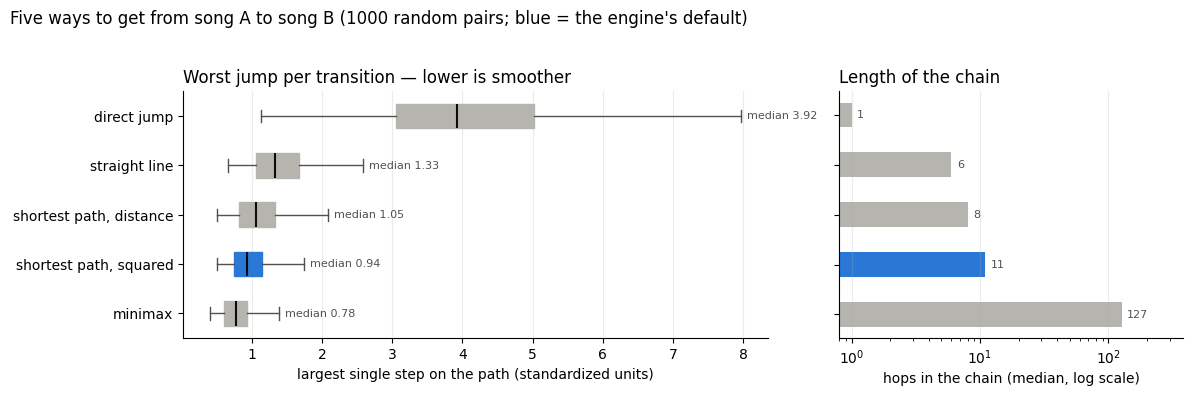

In [18]:
HIGHLIGHT, MUTED, INK = "#2a78d6", "#b5b4ae", "#52514e"
colors = [HIGHLIGHT if m == DEFAULT_METHOD else MUTED for m in METHODS]
ypos = np.arange(len(METHODS))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})

bp = ax[0].boxplot([res[m].max_step for m in METHODS], positions=ypos, vert=False,
                   showfliers=False, widths=0.5, patch_artist=True,
                   medianprops=dict(color="#0b0b0b", lw=1.5),
                   whiskerprops=dict(color=INK, lw=1), capprops=dict(color=INK, lw=1))
for i, (box, c) in enumerate(zip(bp["boxes"], colors)):
    box.set(facecolor=c, edgecolor=c)
    whisker_end = bp["whiskers"][2 * i + 1].get_xdata()[1]
    ax[0].text(whisker_end + 0.08, i, f"median {res[METHODS[i]].max_step.median():.2f}",
               va="center", fontsize=8, color=INK)
ax[0].set_yticks(ypos)
ax[0].set_yticklabels(METHODS)
ax[0].invert_yaxis()
ax[0].set_xlabel("largest single step on the path (standardized units)")
ax[0].set_title("Worst jump per transition — lower is smoother", loc="left")

med_hops = [res[m].hops.median() for m in METHODS]
ax[1].barh(ypos, med_hops, color=colors, height=0.5)
for i, h in enumerate(med_hops):
    ax[1].text(h * 1.1, i, f"{h:.0f}", va="center", fontsize=8, color=INK)
ax[1].set_xscale("log")
ax[1].set_xlim(0.8, max(med_hops) * 3)
ax[1].set_yticks(ypos)
ax[1].set_yticklabels([])
ax[1].invert_yaxis()
ax[1].set_xlabel("hops in the chain (median, log scale)")
ax[1].set_title("Length of the chain", loc="left")

for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="x", alpha=0.25)
fig.suptitle(f"Five ways to get from song A to song B ({N_PAIRS} random pairs; "
             "blue = the engine's default)", x=0.01, ha="left", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation.** Both graph searches beat the two baselines by a wide margin. Cutting
straight from A to B means a median jump of 3.92 standardized units (a typical edge in the
graph is 0.76 long). The straight-line approach still leaves a median worst step of 1.33,
because the real song nearest to a point on the line is often far from it.

Between the two graph searches, squared weights give a smaller worst step in 65% of pairs and
the same one in 31%, cutting the median worst step from 1.05 to 0.94 and the 90th percentile
from 1.62 to 1.38. The price is about three more songs per transition (median 11 hops
instead of 8), and the total distance travelled grows only from 6.12 to 6.73.

The minimax path shows the floor: no path through this graph has a smaller worst step
(median 0.78), but it needs a median of 127 hops, far too long for a set. Squared weights get
within 22% of that floor (median ratio 1.22) with an 11-hop chain, which is why they are the
engine's default.

## 9. Which audio features move most along typical paths?

For each of the 1000 random paths from Section 8 (the default, squared-weight engine), using
the same 10-D standardized space the graph was built on:

- **Net displacement**: `|feature(end) - feature(start)|` — how far apart the two
  endpoints already were on that axis.
- **Arc length**: the sum of `|feature(hop i+1) - feature(hop i)|` across every hop in
  the path — how much ground is actually covered on that axis while walking the chain
  (this can exceed net displacement if the path doubles back on that dimension while
  making progress on others).

The gap between the two shows which axes a path wanders on rather than travels along.

In [19]:
feature_net_disp = np.zeros(len(GRAPH_FEATURES))
feature_arc_length = np.zeros(len(GRAPH_FEATURES))

for path_idx in random_paths:
    feats = X_graph[path_idx]  # (hop_count + 1, 10), standardized units
    feature_net_disp += np.abs(feats[-1] - feats[0])
    feature_arc_length += np.abs(np.diff(feats, axis=0)).sum(axis=0)

n_paths = len(random_paths)
feature_net_disp /= n_paths
feature_arc_length /= n_paths

feature_stats = pd.DataFrame({
    "feature": GRAPH_FEATURES,
    "mean_net_displacement": feature_net_disp,
    "mean_arc_length": feature_arc_length,
    "wander_ratio": feature_arc_length / feature_net_disp,
}).sort_values("mean_arc_length", ascending=False).reset_index(drop=True)

display(feature_stats.round(3))

,feature,mean_net_displacement,mean_arc_length,wander_ratio
0,danceability,1.147,2.047,1.785
1,tempo,1.172,2.042,1.742
2,valence,1.125,2.002,1.780
3,loudness,1.114,1.969,1.767
4,energy,1.153,1.936,1.679
5,acousticness,1.152,1.880,1.633
6,duration_ms,0.802,1.861,2.321
7,liveness,0.908,1.852,2.040
8,speechiness,0.663,1.189,1.793
9,instrumentalness,0.676,0.827,1.223


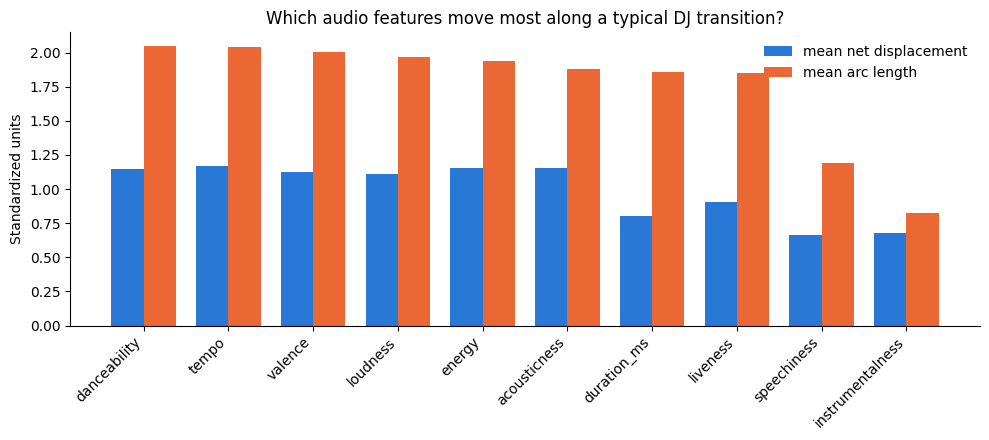

Top 3 axes by arc length: ['danceability', 'tempo', 'valence']


In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(feature_stats))
width = 0.38

ax.bar(x - width/2, feature_stats["mean_net_displacement"], width, label="mean net displacement", color="#2a78d6")
ax.bar(x + width/2, feature_stats["mean_arc_length"], width, label="mean arc length", color="#eb6834")

ax.set_xticks(x)
ax.set_xticklabels(feature_stats["feature"], rotation=45, ha="right")
ax.set_ylabel("Standardized units")
ax.set_title("Which audio features move most along a typical DJ transition?")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

top3 = feature_stats.head(3)["feature"].tolist()
print(f"Top 3 axes by arc length: {top3}")

**Interpretation.** Movement is spread fairly evenly: eight of the ten features cover a similar
amount of ground per path (mean arc length ~1.85–2.05 standardized units), led by
`danceability`, `tempo` and `valence`. No single axis dominates how a transition is built.

The `wander_ratio` column is the more telling one. `duration_ms` (2.32) and `liveness` (2.04)
have by far the highest ratio of ground covered to net progress: paths swing up and down on
them while making their real progress on the other axes. Both are weakly tied to how a track
sounds — duration is heavily skewed by a few very long recordings, and liveness reflects the
recording setting — so neighbouring songs differ on them in no consistent direction. They add
noise rather than signal for a DJ. `instrumentalness` moves least (0.83, ratio 1.22): most
songs sit near zero, so a path only travels on it when one endpoint is instrumental.

## 10. Curated paths export for the website

~50 hand-picked and stratified-sampled song pairs, run through `find_transition` on the default
squared-weight graph and serialized to `outputs/dj_paths.json` so the frontend can render them
without a backend.

**Curation method**: ~20 pairs are hand-picked well-known artists/tracks spanning
same-genre, cross-genre, and cross-decade transitions (including the three Section 7
demos). The remaining ~30 are filled by seeded random sampling from tracks with
popularity >= 60 (so names stay recognizable), weighted 70% toward cross-decade pairs
for variety. Any pair that fails to resolve (ambiguous title, or — should the graph ever
not be fully connected — an unreachable pair) is skipped and reported.

Each path record carries `max_step` and `total_distance` (in the 10-D standardized space) so
the frontend can show how smooth a transition is.

In [21]:
hand_picked = [
    (("Someone Like You", "Adele"), ("Wake Me Up", "Avicii")),
    (("Nancy Mulligan", "Ed Sheeran"), ("New Man", "Ed Sheeran")),
    (("Hello, Goodbye", "Beatles"), ("Levitating", "Dua Lipa")),
    (("Crazy Little Thing Called Love", "Queen"), ("Enter Sandman", "Metallica")),
    (("They Don't Care About Us", "Michael Jackson"), ("Not Afraid", "Eminem")),
    (("I Have Nothing", "Whitney Houston"), ("Umbrella", "Rihanna")),
    (("All Apologies", "Nirvana"), ("Hymn for the Weekend", "Coldplay")),
    (("Space Oddity", "David Bowie"), ("my future", "Billie Eilish")),
    (("Rocket Man", "Elton John"), ("Hung Up", "Madonna")),
    (("Circus", "Britney Spears"), ("Papercut", "Linkin Park")),
    (("Fake Plastic Trees", "Radiohead"), ("HUMBLE.", "Kendrick Lamar")),
    (("You Should Be Dancing", "Bee Gees"), ("Dreams", "Fleetwood Mac")),
    (("We're In This Together", "Nine Inch Nails"), ("Voodoo People", "Prodigy")),
    (("Do It Again", "Chemical Brothers"), ("Ghosts 'n' Stuff", "Deadmau5")),
    (("Scared to Be Lonely", "Martin Garrix"), ("Where Them Girls At", "David Guetta")),
    (("Feel So Close", "Calvin Harris"), ("Be Kind", "Marshmello")),
    (("Mr. Perfectly Fine", "Taylor Swift"), ("DAKITI", "Bad Bunny")),
    (("Dreams", "Fleetwood Mac"), ("my future", "Billie Eilish")),
    (("Enter Sandman", "Metallica"), ("We're In This Together", "Nine Inch Nails")),
    (("I Have Nothing", "Whitney Houston"), ("Someone Like You", "Adele")),
]

hand_picked_ids = []
for (s_name, s_artist), (e_name, e_artist) in hand_picked:
    try:
        s_id = get_song_id(s_name, s_artist)
        e_id = get_song_id(e_name, e_artist)
        hand_picked_ids.append((s_id, e_id))
    except ValueError as exc:
        print(f"  SKIP: {exc}")

print(f"Resolved {len(hand_picked_ids)}/{len(hand_picked)} hand-picked pairs")

  (2 matches for name='Crazy Little Thing Called Love', artist='Queen' -> using the most popular)


  (2 matches for name='Enter Sandman', artist='Metallica' -> using the most popular)


  (4 matches for name='Space Oddity', artist='David Bowie' -> using the most popular)
  (2 matches for name='Papercut', artist='Linkin Park' -> using the most popular)


  (2 matches for name="Ghosts 'n' Stuff", artist='Deadmau5' -> using the most popular)
  SKIP: No track found for name='DAKITI', artist='Bad Bunny'


  (2 matches for name='Enter Sandman', artist='Metallica' -> using the most popular)
Resolved 19/20 hand-picked pairs


In [22]:
rng2 = np.random.RandomState(SEED + 1)
N_EXTRA = 50 - len(hand_picked_ids)

popular = tracks[tracks["popularity"] >= 60].reset_index(drop=True)
decades = sorted(popular["decade"].unique())

extra_ids = []
attempts = 0
while len(extra_ids) < N_EXTRA and attempts < N_EXTRA * 5:
    attempts += 1
    if len(decades) > 1 and rng2.random() < 0.7:
        d1, d2 = rng2.choice(decades, size=2, replace=False)
    else:
        d1 = d2 = rng2.choice(decades)

    row1 = popular[popular["decade"] == d1].sample(1, random_state=rng2.randint(0, 1_000_000)).iloc[0]
    row2 = popular[popular["decade"] == d2].sample(1, random_state=rng2.randint(0, 1_000_000)).iloc[0]

    if row1["id"] == row2["id"]:
        continue
    extra_ids.append((row1["id"], row2["id"]))

print(f"Generated {len(extra_ids)} stratified random pairs to fill out the curated set")

curated_pairs = hand_picked_ids + extra_ids
print(f"Total curated pairs: {len(curated_pairs)}")

Generated 31 stratified random pairs to fill out the curated set
Total curated pairs: 50


In [23]:
def path_to_record(start_id: str, end_id: str, path_ids: list, path_df: pd.DataFrame, total_weight: float) -> dict:
    """Serialize one find_transition() result to the dj_paths.json schema."""
    def song_summary(sid: str) -> dict:
        row = tracks.loc[tracks["id"] == sid].iloc[0]
        return {
            "id": sid,
            "name": row["name"],
            "artist": row["primary_artist_name"],
            "decade": int(row["decade"]),
        }

    path_records = []
    for _, row in path_df.iterrows():
        rec = song_summary(row["id"])
        rec["audio"] = {feat: float(row[feat]) for feat in AUDIO_FEATURES}
        path_records.append(rec)

    steps = path_steps(path_ids)
    return {
        "start": song_summary(start_id),
        "end": song_summary(end_id),
        "path": path_records,
        "total_weight": float(total_weight),          # search cost: sum of squared step lengths
        "total_distance": float(steps.sum()),         # sum of step lengths (10-D standardized)
        "max_step": float(steps.max()),               # the biggest single jump on the path
        "hop_count": len(path_ids) - 1,
    }


dj_paths = []
skipped = 0
for start_id, end_id in curated_pairs:
    path_ids, path_df, total_weight = find_transition(start_id, end_id, DJ_GRAPH, id_to_idx, idx_to_id, tracks)
    if not path_ids or np.isinf(total_weight):
        skipped += 1
        continue
    dj_paths.append(path_to_record(start_id, end_id, path_ids, path_df, total_weight))

print(f"Serialized {len(dj_paths)} paths ({skipped} skipped as unreachable)")

Serialized 50 paths (0 skipped as unreachable)


In [24]:
DJ_PATHS_PATH = OUT_DIR / "dj_paths.json"
with open(DJ_PATHS_PATH, "w", encoding="utf-8") as f:
    json.dump(dj_paths, f, indent=2)

print(f"Saved {len(dj_paths)} curated paths to {DJ_PATHS_PATH} "
      f"({DJ_PATHS_PATH.stat().st_size / 1e3:.1f} KB)")

# Quick eyeball of the mix: hop-count spread should look varied, not clustered at 1.
hop_counts_curated = [p["hop_count"] for p in dj_paths]
max_steps_curated = [p["max_step"] for p in dj_paths]
print(f"Curated hop counts: min={min(hop_counts_curated)}, "
      f"median={int(np.median(hop_counts_curated))}, max={max(hop_counts_curated)}")
print(f"Curated worst steps: median={np.median(max_steps_curated):.3f}, max={max(max_steps_curated):.3f}")

Saved 50 curated paths to outputs\dj_paths.json (323.3 KB)
Curated hop counts: min=3, median=8, max=28
Curated worst steps: median=0.773, max=1.412


## 11. Verification

Simulate a fresh session: reload the saved graph and index from disk only (no reuse of
in-memory objects above), rebuild the squared weights, re-run the Test 1 transition, and
assert it matches. This is what proves `outputs/knn_graph.npz` and `outputs/song_index.json`
are actually usable by another notebook or by the frontend, not just artifacts of this
session's memory.

In [25]:
reloaded_graph = load_npz(OUT_DIR / "knn_graph.npz").power(2)

with open(OUT_DIR / "song_index.json", "r", encoding="utf-8") as f:
    reloaded_index = json.load(f)

reloaded_id_to_idx = reloaded_index["id_to_idx"]
reloaded_idx_to_id = {int(k): v for k, v in reloaded_index["idx_to_id"].items()}

reloaded_path_ids, reloaded_path_df, reloaded_weight = find_transition(
    test1_start, test1_end, reloaded_graph, reloaded_id_to_idx, reloaded_idx_to_id, tracks
)

assert reloaded_path_ids == test1_path_ids, "Reloaded path ids diverged from the original Test 1 run"
assert abs(reloaded_weight - test1_weight) < 1e-9, "Reloaded path weight diverged from the original Test 1 run"

print("OK: reloaded graph + index reproduce the exact Test 1 path and weight.")
print(f"Path length: {len(reloaded_path_ids)} songs, weight: {reloaded_weight:.3f}")

OK: reloaded graph + index reproduce the exact Test 1 path and weight.
Path length: 17 songs, weight: 4.140


## Summary

In [26]:
print("DJ Transition Engine — build summary")
print("=" * 50)
print(f"Graph features:        {len(GRAPH_FEATURES)} continuous ({', '.join(GRAPH_FEATURES)})")
print(f"Nodes:                 {knn_graph.shape[0]:,}")
print(f"Directed edges stored: {knn_graph.nnz:,}  ({K_NEIGHBORS} per node, self-matches removed)")
print(f"Connected components:  {n_components}")
print(f"Edge weights for search: squared Euclidean distance")
print(f"k-NN build time:       {knn_fit_query_time:.1f}s (fit+query) + {graph_build_time:.2f}s (sparse assembly)")
print()
print("Output files:")
for path in [OUT_DIR / "knn_graph.npz", OUT_DIR / "song_index.json", OUT_DIR / "dj_paths.json",
             OUT_DIR / "dj_smoothness_eval.csv"]:
    size_kb = path.stat().st_size / 1e3
    print(f"  {path}  ({size_kb:,.1f} KB)")

DJ Transition Engine — build summary
Graph features:        10 continuous (danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo, duration_ms)
Nodes:                 100,001
Directed edges stored: 1,500,015  (15 per node, self-matches removed)
Connected components:  1
Edge weights for search: squared Euclidean distance
k-NN build time:       95.6s (fit+query) + 0.13s (sparse assembly)

Output files:
  outputs\knn_graph.npz  (15,407.7 KB)
  outputs\song_index.json  (6,777.9 KB)
  outputs\dj_paths.json  (323.3 KB)
  outputs\dj_smoothness_eval.csv  (365.4 KB)
